In [ ]:
#creating files for src folder

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
src = PROJECT_ROOT / "src"
src.mkdir(exist_ok=True)
(src / "__init__.py").write_text("", encoding="utf-8")

io_code = '''"""Helpers for locating and reading raster (GeoTIFF) files."""

from pathlib import Path

import numpy as np
import rasterio


def find_tif(folder, keyword=None):
    """Return the path of the single .tif file in `folder`.

    If `keyword` is given, only file names containing it
    (case-insensitive) are considered.
    """
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")

    candidates = sorted(folder.glob("*.tif"))
    if keyword:
        candidates = [p for p in candidates if keyword.lower() in p.name.lower()]

    if not candidates:
        raise FileNotFoundError(f"No matching .tif file in {folder}")
    if len(candidates) > 1:
        raise ValueError(f"Several files match: {[p.name for p in candidates]}")
    return candidates[0]


def load_raster(path, nodata_to_nan=False):
    """Read band 1 of a raster. Returns (array, profile).

    If nodata_to_nan is True, nodata pixels become NaN (array turns float32).
    """
    with rasterio.open(path) as src:
        array = src.read(1)
        profile = src.profile

    nodata = profile.get("nodata")
    if nodata_to_nan and nodata is not None:
        array = array.astype("float32")
        array[array == nodata] = np.nan

    return array, profile
'''

viz_code = '''"""Functions for plotting raster maps and exporting them as images."""

from pathlib import Path

import matplotlib.pyplot as plt


def save_map(array, title, output_path, cmap="viridis", cbar_label="",
             vmin=None, vmax=None, dpi=600):
    """Plot a 2D array with a colorbar and save it as an image (600 dpi default)."""
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(array, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("Column (pixel)")
    ax.set_ylabel("Row (pixel)")
    fig.colorbar(im, ax=ax, label=cbar_label)

    fig.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)
'''

(src / "io_utils.py").write_text(io_code, encoding="utf-8")
(src / "visualization.py").write_text(viz_code, encoding="utf-8")
print([p.name for p in src.iterdir()])

['io_utils.py', 'visualization.py', '__init__.py', '__pycache__']


hazard  shape=(360, 360) dtype=float32 min=0 max=1
slope   shape=(360, 360) dtype=float32 min=0 max=67.6
stream  shape=(360, 360) dtype=int16 min=0 max=8


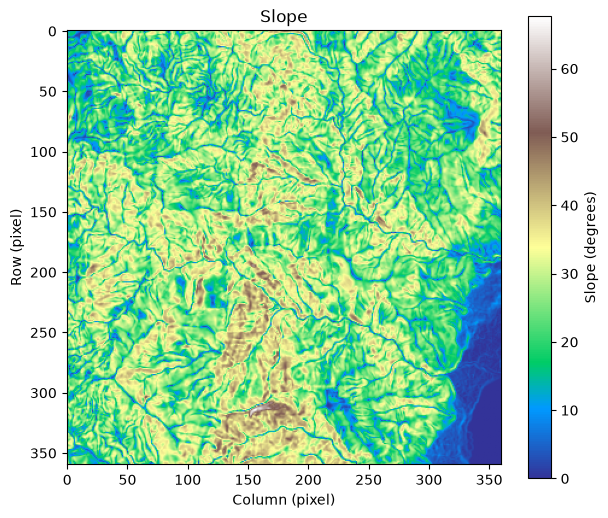

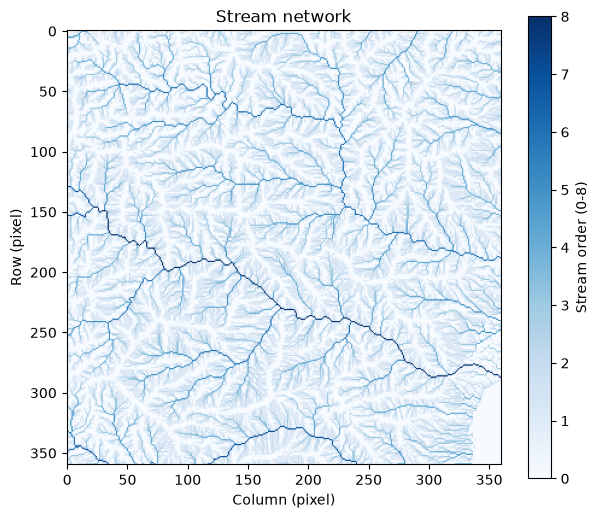

slope.png 0.7 MB
stream_network.png 0.3 MB


In [2]:
import sys
from pathlib import Path

import numpy as np

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.io_utils import find_tif, load_raster
from src.visualization import save_map

DATA_DIR = PROJECT_ROOT / "data"
LAND_DIR = DATA_DIR / "Land_surface_data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# ---- Task 1: load the three maps as numpy arrays ----
hazard, hazard_profile = load_raster(find_tif(DATA_DIR / "Natural_hazard_image"),
                                     nodata_to_nan=True)
slope, _ = load_raster(find_tif(LAND_DIR, "slope"))
stream, _ = load_raster(find_tif(LAND_DIR, "stream"))

for name, array in {"hazard": hazard, "slope": slope, "stream": stream}.items():
    print(f"{name:7s} shape={array.shape} dtype={array.dtype} "
          f"min={np.nanmin(array):.3g} max={np.nanmax(array):.3g}")

# ---- Task 2: export slope and stream network at 600 dpi ----
save_map(slope, "Slope", OUTPUT_DIR / "slope.png",
         cmap="terrain", cbar_label="Slope (degrees)")

save_map(stream, "Stream network", OUTPUT_DIR / "stream_network.png",
         cmap="Blues", cbar_label="Stream order (0-8)", vmin=0, vmax=8)
for f in sorted(OUTPUT_DIR.glob("*.png")):
    print(f.name, f"{f.stat().st_size / 1e6:.1f} MB")